# ISIC 2020 — Lightweight CNN v1 and v2

Two from-scratch CNN architectures evaluated on the same patient-level training/validation split. The test split is deliberately not evaluated in this notebook.

**Prerequisites:** cached `images_uint8_new.npy`, corresponding `metadata.csv`, and the shared project `isic_utils.py`. Paths in the setup cell are Colab defaults and can be edited. Run cells sequentially.

**AI assistance disclosure:** AI tools were used to assist with code development, debugging, and documentation; results were obtained from the actual experiments.

**Recorded outputs:** The training logs, validation metrics, and plots below are preserved from the original Colab run. They are not freshly executed by this cleaned notebook. Dataset and shared utilities must be available to rerun.

## 1. Imports, paths, and dataset

Uses the shared `CachedISIC` and `build_transforms` utilities, matching the team preprocessing. The metadata is split by `split_patient`, not by image-level random assignment.

In [ ]:
import sys
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

# Edit these paths for your environment.
sys.path.insert(0, "/content/isic")
import isic_utils as U

meta = pd.read_csv("/content/isic/metadata.csv")
print(meta["split_patient"].value_counts())


In [ ]:
import sys
sys.path.insert(0, "/content/isic")

import isic_utils as U
from torch.utils.data import DataLoader

# Configuration
CACHE_PATH = "/content/images_uint8_new.npy"  # Change to your local cache path
IMG_SIZE = 224
BATCH_SIZE = 64

# Patient-level training and validation splits
train_meta = meta[meta["split_patient"] == "train"]
val_meta = meta[meta["split_patient"] == "val"]

# Datasets
train_dataset = U.CachedISIC(
    CACHE_PATH,
    train_meta["cache_index"].to_numpy(),
    train_meta["target"].to_numpy(),
    U.build_transforms(IMG_SIZE, train=True)
)

val_dataset = U.CachedISIC(
    CACHE_PATH,
    val_meta["cache_index"].to_numpy(),
    val_meta["target"].to_numpy(),
    U.build_transforms(IMG_SIZE, train=False)
)

# DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

# Verify one batch
X, y = next(iter(train_loader))

print("Image batch shape:", X.shape)
print("Label batch shape:", y.shape)

Training images: 23364
Validation images: 4663
Image batch shape: torch.Size([64, 3, 224, 224])
Label batch shape: torch.Size([64])


## 2. CNN v1 — 2 convolutional layers

Original baseline: 19,457 trainable parameters. AdamW, square-root positive class weighting, 2-epoch warmup and cosine decay, 20-epoch maximum, and patience 5. Best checkpoint selected by validation AUPRC.

In [ ]:
import torch
import torch.nn as nn

class LightweightCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = LightweightCNN().to(device)

print("Device:", device)
print("Trainable parameters:", sum(p.numel() for p in model.parameters()))

with torch.no_grad():
    output = model(X.to(device))

print("Output shape:", output.shape)


Device: cuda
Trainable parameters: 19457
Output shape: torch.Size([64])


In [ ]:
import numpy as np
import torch.nn as nn
import torch.optim as optim

# Calculate class imbalance from training data only
positive = (train_meta["target"] == 1).sum()
negative = (train_meta["target"] == 0).sum()

pos_weight = np.sqrt(negative / positive)

print("Malignant:", positive)
print("Benign:", negative)
print("Positive weight:", pos_weight)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight], dtype=torch.float32, device=device
    )
)

optimizer = optim.AdamW(
    model.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

Malignant: 414
Benign: 22950
Positive weight: 7.445453821540743


In [ ]:
import math

EPOCHS = 20
WARMUP_EPOCHS = 2
PATIENCE = 5

steps_per_epoch = len(train_loader)
total_steps = EPOCHS * steps_per_epoch
warmup_steps = WARMUP_EPOCHS * steps_per_epoch

def lr_lambda(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps

    progress = (step - warmup_steps) / max(
        1, total_steps - warmup_steps
    )

    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler = torch.optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lr_lambda
)

best_auprc = -1.0
patience_counter = 0

In [ ]:
from sklearn.metrics import average_precision_score, roc_auc_score
from tqdm.auto import tqdm
import numpy as np
import torch
import copy

history = {
    "train_loss": [],
    "val_loss": [],
    "val_auprc": [],
    "val_auroc": []
}

best_state = None

for epoch in range(EPOCHS):

    # ---------- TRAINING ----------
    model.train()
    running_loss = 0.0

    for images_batch, labels_batch in tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}"
    ):
        images_batch = images_batch.to(device, non_blocking=True)
        labels_batch = labels_batch.to(device, non_blocking=True)

        optimizer.zero_grad()

        logits = model(images_batch)
        loss = criterion(logits, labels_batch)

        loss.backward()
        optimizer.step()
        scheduler.step()

        running_loss += loss.item() * labels_batch.size(0)

    train_loss = running_loss / len(train_dataset)

    # ---------- VALIDATION ----------
    model.eval()
    val_running_loss = 0.0
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images_batch, labels_batch in val_loader:
            images_batch = images_batch.to(device, non_blocking=True)
            labels_batch = labels_batch.to(device, non_blocking=True)

            logits = model(images_batch)
            loss = criterion(logits, labels_batch)

            probs = torch.sigmoid(logits)

            val_running_loss += loss.item() * labels_batch.size(0)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels_batch.cpu().numpy())

    val_loss = val_running_loss / len(val_dataset)

    val_auprc = average_precision_score(all_labels, all_probs)
    val_auroc = roc_auc_score(all_labels, all_probs)

    # ---------- SAVE HISTORY ----------
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_auprc"].append(val_auprc)
    history["val_auroc"].append(val_auroc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"AUPRC: {val_auprc:.4f} | "
        f"AUROC: {val_auroc:.4f}"
    )

    # ---------- EARLY STOPPING ----------
    if val_auprc > best_auprc:
        best_auprc = val_auprc
        patience_counter = 0

        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            best_state,
            "/content/best_lightweight_cnn.pth"
        )

        print("Best model saved!")

    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

# Restore best validation checkpoint
if best_state is not None:
    model.load_state_dict(best_state)

print(f"\nBest Validation AUPRC: {best_auprc:.4f}")

Epoch 1/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 1/20 | Train Loss: 0.5787 | Val Loss: 0.3684 | AUPRC: 0.0417 | AUROC: 0.7401
Best model saved!


Epoch 2/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 2/20 | Train Loss: 0.3799 | Val Loss: 0.3745 | AUPRC: 0.0465 | AUROC: 0.7573
Best model saved!


Epoch 3/20:   0%|          | 0/366 [00:00<?, ?it/s]

...

Epoch 14/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 14/20 | Train Loss: 0.3667 | Val Loss: 0.3697 | AUPRC: 0.0481 | AUROC: 0.7451


Epoch 15/20:   0%|          | 0/366 [00:00<?, ?it/s]

    : 


Epoch 15/20 | Train Loss: 0.3656 | Val Loss: 0.3700 | AUPRC: 0.0485 | AUROC: 0.7449
Early stopping triggered.
Best Validation AUPRC: 0.0498


### CNN v1 validation evaluation and exports

F1 threshold is selected on validation data; these threshold-dependent validation metrics are optimistic and should not be interpreted as independent test results.

In [ ]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    precision_recall_curve,
    roc_curve
)

model.load_state_dict(
    torch.load(
        "/content/best_lightweight_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

val_probs = []
val_labels = []

with torch.no_grad():
    for images_batch, labels_batch in val_loader:
        images_batch = images_batch.to(device)

        logits = model(images_batch)
        probs = torch.sigmoid(logits)

        val_probs.extend(probs.cpu().numpy())
        val_labels.extend(labels_batch.numpy())

val_probs = np.array(val_probs)
val_labels = np.array(val_labels).astype(int)

print("Validation samples:", len(val_labels))
print("Malignant samples:", val_labels.sum())
print("AUPRC:", average_precision_score(val_labels, val_probs))
print("AUROC:", roc_auc_score(val_labels, val_probs))

Validation samples: 4663
Malignant samples: 85
AUPRC: 0.04980837755372397
AUROC: 0.7481561431912215


In [ ]:
precision_curve, recall_curve, thresholds = precision_recall_curve(
    val_labels, val_probs
)

f1_values = (
    2 * precision_curve[:-1] * recall_curve[:-1]
    / (precision_curve[:-1] + recall_curve[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
best_threshold = float(thresholds[best_idx])

val_preds = (val_probs >= best_threshold).astype(int)

metrics = {
    "AUPRC": average_precision_score(val_labels, val_probs),
    "AUROC": roc_auc_score(val_labels, val_probs),
    "Precision": precision_score(val_labels, val_preds, zero_division=0),
    "Recall": recall_score(val_labels, val_preds, zero_division=0),
    "F1": f1_score(val_labels, val_preds, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(val_labels, val_preds),
    "Threshold": best_threshold
}

tn, fp, fn, tp = confusion_matrix(
    val_labels, val_preds, labels=[0, 1]
).ravel()

metrics.update({
    "TP": int(tp),
    "FP": int(fp),
    "FN": int(fn),
    "TN": int(tn)
})

print(pd.Series(metrics).round(4))

AUPRC                   0.0498
AUROC                   0.7482
Precision               0.0701
Recall                  0.1765
F1                      0.1003
Balanced Accuracy       0.5665
Threshold               0.2287
TP                     15.0000
FP                    199.0000
FN                     70.0000
TN                   4379.0000
dtype: float64


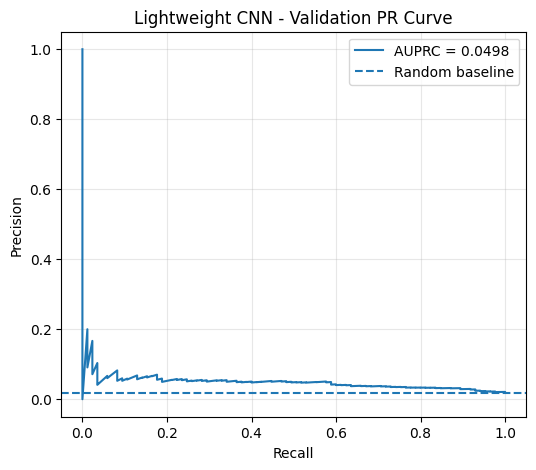

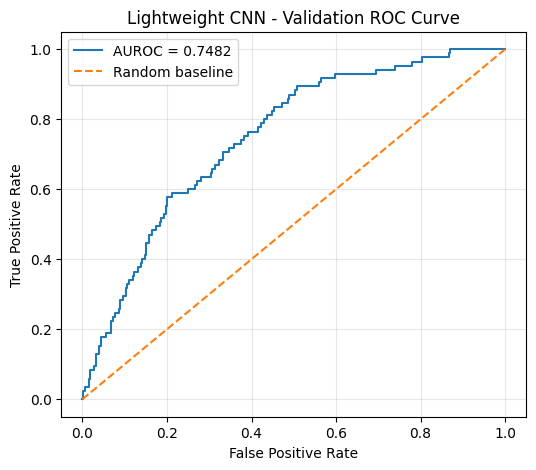

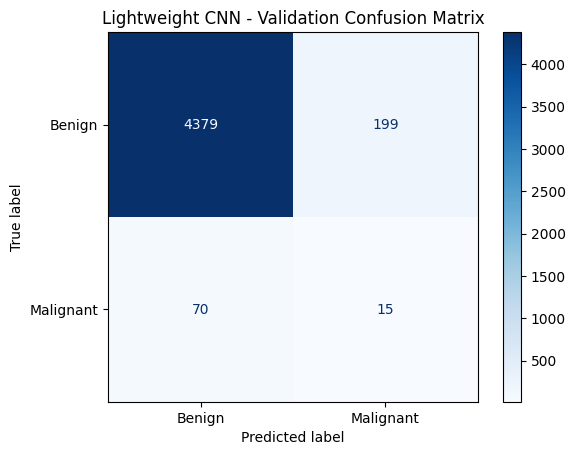

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
from pathlib import Path

SAVE_DIR = Path("/content/lightweight_cnn_results")
SAVE_DIR.mkdir(exist_ok=True)

# Precision-Recall curve
plt.figure(figsize=(6, 5))
plt.plot(recall_curve, precision_curve,
         label=f"AUPRC = {metrics['AUPRC']:.4f}")
plt.axhline(val_labels.mean(), linestyle="--",
            label="Random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Lightweight CNN - Validation PR Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(SAVE_DIR / "pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(val_labels, val_probs)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUROC = {metrics['AUROC']:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Lightweight CNN - Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(SAVE_DIR / "roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# Confusion matrix
cm = confusion_matrix(val_labels, val_preds, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Lightweight CNN - Validation Confusion Matrix")
plt.savefig(SAVE_DIR / "confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
import json
import shutil

# Metrics
with open(SAVE_DIR / "metrics.json", "w") as f:
    json.dump(metrics, f, indent=4)

# Predictions, in the same order as val_meta
predictions_df = val_meta[
    ["cache_index", "target"]
].reset_index(drop=True).copy()

predictions_df["probability_malignant"] = val_probs
predictions_df["predicted_label"] = val_preds

predictions_df.to_csv(
    SAVE_DIR / "validation_predictions.csv",
    index=False
)

# Training history
pd.DataFrame(history).to_csv(
    SAVE_DIR / "training_history.csv",
    index=False
)

# Best model
shutil.copy2(
    "/content/best_lightweight_cnn.pth",
    SAVE_DIR / "best_lightweight_cnn.pth"
)

# Bundle everything
shutil.make_archive(
    "/content/lightweight_cnn_results",
    "zip",
    SAVE_DIR
)

print("Saved:", "/content/lightweight_cnn_results.zip")

Saved: /content/lightweight_cnn_results.zip


## 3. CNN v2 — 3 convolutional layers + BatchNorm

Improved architecture: 93,825 trainable parameters. Trained from scratch with the same dataset, preprocessing, and optimization policy. Both depth and BatchNorm change, so this is a combined architectural comparison.

In [ ]:
import torch
import torch.nn as nn

class LightweightCNNv2(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x).squeeze(1)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_v2 = LightweightCNNv2().to(device)

print("Device:", device)
print("Trainable parameters:",
      sum(p.numel() for p in model_v2.parameters()))

with torch.no_grad():
    output = model_v2(X.to(device))

print("Output shape:", output.shape)

Device: cuda
Trainable parameters: 93825
Output shape: torch.Size([64])


In [ ]:
import math
import torch
import torch.nn as nn
import torch.optim as optim

# Same class weighting as CNN v1
criterion_v2 = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [pos_weight],
        dtype=torch.float32,
        device=device
    )
)

# Fresh optimizer for CNN v2
optimizer_v2 = optim.AdamW(
    model_v2.parameters(),
    lr=2e-4,
    weight_decay=1e-4
)

# Same training configuration
EPOCHS_V2 = 20
WARMUP_EPOCHS_V2 = 2
PATIENCE_V2 = 5

steps_per_epoch_v2 = len(train_loader)
total_steps_v2 = EPOCHS_V2 * steps_per_epoch_v2
warmup_steps_v2 = WARMUP_EPOCHS_V2 * steps_per_epoch_v2

def lr_lambda_v2(step):
    if step < warmup_steps_v2:
        return (step + 1) / warmup_steps_v2

    progress = (step - warmup_steps_v2) / max(
        1, total_steps_v2 - warmup_steps_v2
    )

    return 0.5 * (1 + math.cos(math.pi * progress))

scheduler_v2 = torch.optim.lr_scheduler.LambdaLR(
    optimizer_v2,
    lr_lambda=lr_lambda_v2
)

best_auprc_v2 = -1.0
patience_counter_v2 = 0

print("CNN v2 training configuration ready!")

CNN v2 training configuration ready!


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [ ]:
import torch
import numpy as np
import pandas as pd
import copy
import time
from tqdm.auto import tqdm
from sklearn.metrics import average_precision_score, roc_auc_score

history_v2 = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_auprc": [],
    "val_auroc": [],
    "epoch_time_seconds": []
}

best_state_v2 = None
best_epoch_v2 = 0
best_auprc_v2 = -1.0
patience_counter_v2 = 0

for epoch in range(EPOCHS_V2):

    start_time = time.time()

    # ---------- TRAINING ----------
    model_v2.train()
    running_loss = 0.0

    for images_batch, labels_batch in tqdm(
        train_loader,
        desc=f"CNN v2 Epoch {epoch+1}/{EPOCHS_V2}"
    ):
        images_batch = images_batch.to(device, non_blocking=True)
        labels_batch = labels_batch.to(device, non_blocking=True)

        optimizer_v2.zero_grad()

        logits = model_v2(images_batch)
        loss = criterion_v2(logits, labels_batch)

        loss.backward()
        optimizer_v2.step()
        scheduler_v2.step()

        running_loss += loss.item() * labels_batch.size(0)

    train_loss = running_loss / len(train_dataset)

    # ---------- VALIDATION ----------
    model_v2.eval()
    val_running_loss = 0.0
    all_probs = []
    all_labels = []

    with torch.no_grad():
        for images_batch, labels_batch in val_loader:
            images_batch = images_batch.to(device, non_blocking=True)
            labels_batch = labels_batch.to(device, non_blocking=True)

            logits = model_v2(images_batch)
            loss = criterion_v2(logits, labels_batch)

            probs = torch.sigmoid(logits)

            val_running_loss += loss.item() * labels_batch.size(0)

            all_probs.extend(probs.cpu().numpy())
            all_labels.extend(labels_batch.cpu().numpy())

    val_loss = val_running_loss / len(val_dataset)

    val_auprc = average_precision_score(all_labels, all_probs)
    val_auroc = roc_auc_score(all_labels, all_probs)

    epoch_time = time.time() - start_time

    # ---------- LOG RESULTS ----------
    history_v2["epoch"].append(epoch + 1)
    history_v2["train_loss"].append(train_loss)
    history_v2["val_loss"].append(val_loss)
    history_v2["val_auprc"].append(val_auprc)
    history_v2["val_auroc"].append(val_auroc)
    history_v2["epoch_time_seconds"].append(epoch_time)

    print(
        f"Epoch {epoch+1}/{EPOCHS_V2} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"AUPRC: {val_auprc:.4f} | "
        f"AUROC: {val_auroc:.4f} | "
        f"Time: {epoch_time:.1f}s"
    )

    # Save history after every epoch
    pd.DataFrame(history_v2).to_csv(
        "/content/cnn_v2_training_history.csv",
        index=False
    )

    # ---------- BEST CHECKPOINT ----------
    if val_auprc > best_auprc_v2:
        best_auprc_v2 = val_auprc
        best_epoch_v2 = epoch + 1
        patience_counter_v2 = 0

        best_state_v2 = copy.deepcopy(model_v2.state_dict())

        torch.save(
            best_state_v2,
            "/content/best_lightweight_cnn_v2.pth"
        )

        print("New best CNN v2 checkpoint saved!")

    else:
        patience_counter_v2 += 1

        if patience_counter_v2 >= PATIENCE_V2:
            print("Early stopping triggered.")
            break

# Restore best checkpoint
if best_state_v2 is not None:
    model_v2.load_state_dict(best_state_v2)

print("\nCNN v2 Training Complete")
print("Best epoch:", best_epoch_v2)
print(f"Best validation AUPRC: {best_auprc_v2:.4f}")
print(f"Total training time: {sum(history_v2['epoch_time_seconds']) / 60:.2f} minutes")

CNN v2 Epoch 1/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 1/20 | Train Loss: 0.5062 | Val Loss: 0.4105 | AUPRC: 0.0371 | AUROC: 0.6595 | Time: 245.1s
New best CNN v2 checkpoint saved!


CNN v2 Epoch 2/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 2/20 | Train Loss: 0.3907 | Val Loss: 0.3820 | AUPRC: 0.0421 | AUROC: 0.7140 | Time: 223.4s
New best CNN v2 checkpoint saved!


CNN v2 Epoch 3/20:   0%|          | 0/366 [00:00<?, ?it/s]

...

Epoch 18/20 | Train Loss: 0.3234 | Val Loss: 0.3528 | AUPRC: 0.0698 | AUROC: 0.7859 | Time: 228.9s


CNN v2 Epoch 19/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 19/20 | Train Loss: 0.3259 | Val Loss: 0.3465 | AUPRC: 0.0721 | AUROC: 0.7968 | Time: 227.6s
New best CNN v2 checkpoint saved!


CNN v2 Epoch 20/20:   0%|          | 0/366 [00:00<?, ?it/s]

Epoch 20/20 | Train Loss: 0.3228 | Val Loss: 0.3421 | AUPRC: 0.0778 | AUROC: 0.7978 | Time: 231.9s
New best CNN v2 checkpoint saved!
CNN v2 Training Complete
Best epoch: 20
Best validation AUPRC: 0.0778
Total training time: 76.16 minutes


### CNN v2 validation evaluation and exports

In [ ]:
import torch
import numpy as np
import pandas as pd
from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    balanced_accuracy_score, confusion_matrix,
    precision_recall_curve
)

model_v2.load_state_dict(
    torch.load(
        "/content/best_lightweight_cnn_v2.pth",
        map_location=device,
        weights_only=True
    )
)
model_v2.eval()

probs_v2 = []
labels_v2 = []

with torch.no_grad():
    for xb, yb in val_loader:
        logits = model_v2(xb.to(device))
        probs_v2.extend(torch.sigmoid(logits).cpu().numpy())
        labels_v2.extend(yb.numpy())

probs_v2 = np.array(probs_v2)
labels_v2 = np.array(labels_v2).astype(int)

precision, recall, thresholds = precision_recall_curve(
    labels_v2, probs_v2
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_threshold_v2 = float(thresholds[np.argmax(f1_scores)])
preds_v2 = (probs_v2 >= best_threshold_v2).astype(int)

metrics_v2 = {
    "AUPRC": average_precision_score(labels_v2, probs_v2),
    "AUROC": roc_auc_score(labels_v2, probs_v2),
    "Precision": precision_score(labels_v2, preds_v2, zero_division=0),
    "Recall": recall_score(labels_v2, preds_v2, zero_division=0),
    "F1": f1_score(labels_v2, preds_v2, zero_division=0),
    "Balanced Accuracy": balanced_accuracy_score(labels_v2, preds_v2),
    "Threshold": best_threshold_v2
}

tn, fp, fn, tp = confusion_matrix(
    labels_v2, preds_v2, labels=[0, 1]
).ravel()

metrics_v2.update({
    "TP": int(tp), "FP": int(fp),
    "FN": int(fn), "TN": int(tn)
})

print(pd.Series(metrics_v2).round(4))

AUPRC                   0.0778
AUROC                   0.7978
Precision               0.1236
Recall                  0.1294
F1                      0.1264
Balanced Accuracy       0.5562
Threshold               0.3575
TP                     11.0000
FP                     78.0000
FN                     74.0000
TN                   4500.0000
dtype: float64


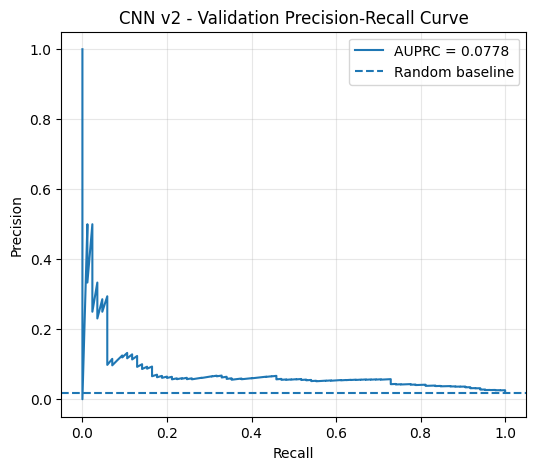

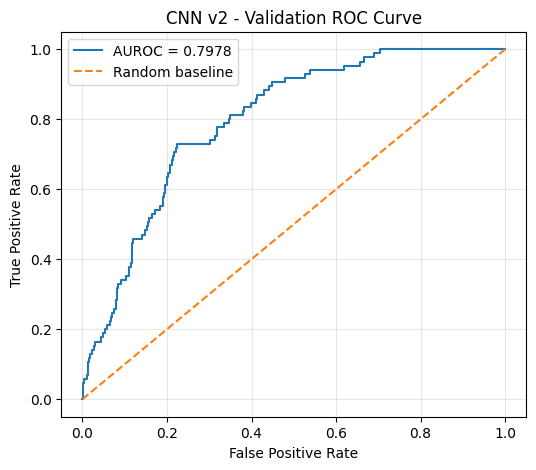

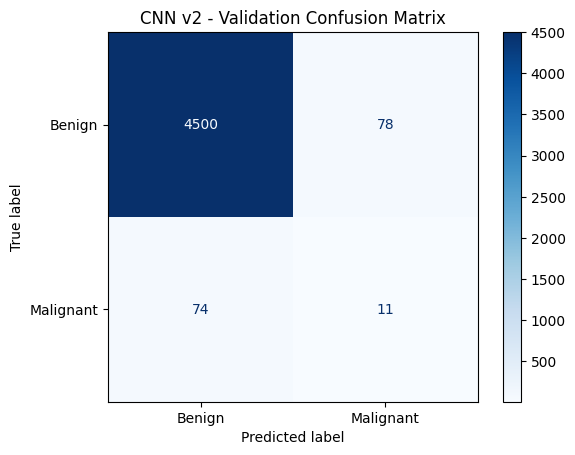

Saved: /content/lightweight_cnn_v2_results.zip


In [ ]:
import json
import shutil
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, roc_curve

save_dir_v2 = Path("/content/lightweight_cnn_v2_results")
save_dir_v2.mkdir(exist_ok=True)

# Save metrics
with open(save_dir_v2 / "metrics.json", "w") as f:
    json.dump(metrics_v2, f, indent=4)

# Save validation predictions
predictions_v2 = val_meta[
    ["cache_index", "target"]
].reset_index(drop=True).copy()

predictions_v2["probability_malignant"] = probs_v2
predictions_v2["predicted_label"] = preds_v2

predictions_v2.to_csv(
    save_dir_v2 / "validation_predictions.csv",
    index=False
)

# Save training history
pd.DataFrame(history_v2).to_csv(
    save_dir_v2 / "training_history.csv",
    index=False
)

# Save model checkpoint
shutil.copy2(
    "/content/best_lightweight_cnn_v2.pth",
    save_dir_v2 / "best_lightweight_cnn_v2.pth"
)

# Precision-recall curve
plt.figure(figsize=(6, 5))
plt.plot(recall, precision, label=f"AUPRC = {metrics_v2['AUPRC']:.4f}")
plt.axhline(labels_v2.mean(), linestyle="--", label="Random baseline")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("CNN v2 - Validation Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(save_dir_v2 / "pr_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(labels_v2, probs_v2)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUROC = {metrics_v2['AUROC']:.4f}")
plt.plot([0, 1], [0, 1], "--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("CNN v2 - Validation ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(save_dir_v2 / "roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

# Confusion matrix
cm = confusion_matrix(labels_v2, preds_v2, labels=[0, 1])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("CNN v2 - Validation Confusion Matrix")
plt.savefig(
    save_dir_v2 / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Create ZIP
shutil.make_archive(
    "/content/lightweight_cnn_v2_results",
    "zip",
    save_dir_v2
)

print("Saved: /content/lightweight_cnn_v2_results.zip")

## 4. Reported validation results

| Metric | CNN v1 | CNN v2 |
|---|---:|---:|
| AUPRC | 0.0498 | 0.0778 |
| AUROC | 0.7482 | 0.7978 |
| Precision (val F1 threshold) | 0.0701 | 0.1236 |
| Recall (val F1 threshold) | 0.1765 | 0.1294 |
| F1 | 0.1003 | 0.1264 |
| Trainable parameters | 19,457 | 93,825 |

These figures were observed in the original run, not recomputed when preparing this clean notebook. CNN v2 best epoch: 20, training duration: 76.16 minutes. Validation: 4,663 images including 85 malignant cases.

**Limitations:** Both models have low melanoma recall at their respective F1-optimized thresholds. Results are not suitable for clinical use. No held-out test results are claimed.

In [2]:
import numpy as np

confusion_matrices = {
    "CNN v1": (15, 199, 70, 4379),
    "CNN v2": (11, 78, 74, 4500)
}

for model, (tp, fp, fn, tn) in confusion_matrices.items():
    accuracy = (tp + tn) / (tp + fp + fn + tn)
    specificity = tn / (tn + fp)
    mcc = (tp * tn - fp * fn) / np.sqrt(
        (tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)
    )

    print(f"{model}")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Specificity: {specificity:.4f}")
    print(f"MCC: {mcc:.4f}\n")

CNN v1
Accuracy: 0.9423
Specificity: 0.9565
MCC: 0.0850

CNN v2
Accuracy: 0.9674
Specificity: 0.9830
MCC: 0.1099

